Compare active and idle states of IOT devices

Code structure: if possible have data and display independent, so that time can be saved by not recomputing unchanged data

e.g

```python
show_data(get_data())
```

rather than

```python
def show_data():
    get_data()
```

also increases configurability

Terms:

- Class
- Window (w seconds long)
- Shift (s seconds)


In [53]:
# function defs

from enum import StrEnum
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
from colorhash import ColorHash
from functools import reduce
from collections import Counter
import matplotlib.style as mplstyle
from dataclasses import dataclass
import pprint

pp = pprint.PrettyPrinter(indent=4, width=100)

mplstyle.use("fast")
import doctest


class State(StrEnum):
    ACTIVE = "active"
    IDLE = "idle"


class Metric(StrEnum):
    MEAN = "mean"
    STD = "std"
    BOTH = "both"
    MEAN_NO_OUTLIERS = "mean_no_outliers"

    def fancy_name(self):
        match self.value:
            case "mean":
                return "μ"
            case "std":
                return "σ"
            case _:
                return self.value


class Data:
    def __init__(self, context, device: Device, state: State):
        self.device = device
        self.state = state
        data = pd.read_csv(
            f"{context.path}/{device.category}/{device.dir_name}/{state}.csv",
            parse_dates=["timestamp"],
        )
        if device.dir_name == "nestmini2":
            data = data.rename(columns={"power_W": "power_mW"})

        split = (
            25
            * 60
            # 25 minutes of training data, gurantees at least 10 minutes of testing data
        )
        self.training = data.iloc[:split, :]
        self.testing = data.iloc[split:, :]


def category_sort_order(cat):
    match cat:
        case "appliance":
            return 5
        case "tv":
            return 4
        case "lights":
            return 1
        case "audio":
            return 2
        case "camera":
            return 3
        case _:
            raise ValueError(cat)


class Context:
    """
    Get all the devices and categories.

    Hard coded to remove echodot3 since the idle data is truncated and can't be compared
    >>> c = Context('../PowerIDS/classifier/power_csv')
    >>> len(c.devices)
    32

    >>> c.categories
    ['lights', 'audio', 'camera', 'tv', 'appliance']

    >>> len(c.data)
    64

    >>> all(['power_mW' in data.training.columns for data in c.data])
    True

    >>> all(['power_mW' in data.testing.columns for data in c.data])
    True

    >>> c.devices[:5]
    [Antela Light, Fitop Light, LIFX Light, Lepro Light, Tapo Light]
    """

    def __init__(self, path: str):
        self.path = path
        self.categories = sorted(os.listdir(path), key=category_sort_order)
        self.devices = sorted(
            [
                Device(device, category)
                for category in self.categories
                for device in os.listdir(f"{path}/{category}")
                if device != "echodot3"
            ],
            key=lambda device: (category_sort_order(device.category), device.name()),
        )
        # The global pool of data for all the states we care about
        self.data = [
            Data(self, device, state) for state in State for device in self.devices
        ]
        # truncate the testing data to the shortest one
        least = min([len(data.testing) for data in self.data])
        for data in self.data:
            data.testing = data.testing.iloc[:least, :]


def map_device_names(name):
    match name:
        case "appletv":
            return "Apple TV"
        case "LGtv":
            return "LG TV"
        case "samsungtv":
            return 'Samsung 32" TV'
        case "samsungtvsmall":
            return "Samsung Small TV"
        case "tcltv":
            return "TCL TV"
        case "toshiba":
            return "Toshiba TV"
        case "yeelight4":
            return "Yeelight Light"
        case "wiz":
            return "Wiz Light"
        case "tapo":
            return "Tapo Light"
        case "lifx":
            return "LIFX Light"
        case "lepro":
            return "Lepro Light"
        case "fitop":
            return "Fitop Light"
        case "antela":
            return "Antela Light"
        case "yibefb":
            return "Yi Camera"
        case "hualai":
            return "Hualai Camera"
        case "google1d15":
            return "Google Nest Camera"
        case "boifun80c0":
            return "Boifun Baby Camera"
        case "bluram6da9":
            return "Blurams Camera"
        case "amcrest266e":
            return "Amcrest Camera"
        case "bose":
            return "Bose Speaker"
        case "echodot3":
            return "Echo Dot 3 Speaker"
        case "echodot5":
            return "Echo Dot 5 Speaker"
        case "echospot":
            return "Echo Spot 5 Speaker"
        case "googlehome":
            return "Google Home Speaker"
        case "homepod":
            return "Homepod Speaker"
        case "nestmini2":
            return "Nest Mini 2 Speaker"
        case "sonos":
            return "Sonos Speaker"
        case "cosori":
            return "Cosori Air Fryer"
        case "honeywell":
            return "Honeywell Thermostat"
        case "levoit":
            return "Levoit Air Purifier"
        case "swan":
            return "Swan Smart Kettle"
        case "xiaomiblender":
            return "Xiaomi Blender"
        case "weekett":
            return "Weekett Kettle"


class Device:
    def __init__(self, dir_name: str, category):
        self.dir_name: str = dir_name
        self.category = category
        self.nice_name = map_device_names(dir_name)
        self.colour = ColorHash(dir_name).hex

    def __str__(self):
        return self.name()

    def __repr__(self):
        return self.name()

    # Get the nice name if needed
    def name(self):
        if self.nice_name:
            return self.nice_name
        else:
            return self.dir_name


class Experiment:
    """
    Verify the new devices are seperate

    >>> e = Context('../PowerIDS/classifier/power_csv')
    >>> exp = Experiment(e, State.IDLE, 'mean', 180, 10, )
    >>> e.devices.pop()
    Xiaomi Blender
    >>> len(exp.devices)
    32

    >>> len(exp.data)
    32

    >>> all(['power_mW' in data.training.columns for data in exp.data])
    True

    >>> all(['power_mW' in data.testing.columns for data in exp.data])
    True

    Filtering
    >>> len(Experiment(e, State.IDLE, Metric.MEAN, 180, 10, include=['appletv', 'samsungtv', 'cosori']).devices)
    3
    """

    def __init__(
        self, context: Context, state: State, metric: Metric, w, s, include=[]
    ):
        self.context = context
        self.metric = metric
        if include == []:
            include = list(map(lambda device: device.dir_name, context.devices))
        self.devices = [
            device for device in context.devices if device.dir_name in include
        ]
        self.data: list[Data] = [
            data
            for data in context.data
            if (data.device.dir_name in include and data.state == state)
        ]
        if w > 600:
            raise ValueError(w)
        self.w: int = w
        self.s: int = s
        self.state: State = state
        self.classes = self.classify_data()
        self.confusion_matrix = self.compute_confusion_matrix()
        self.f1_scores = self.compute_f1_scores()
        self.precision = self.compute_precision()
        self.f1_macro_average = sum(self.f1_scores.values()) / len(self.f1_scores)

    def classify_data(self: Experiment):
        """
        for each of the testing datasets in an experiment, predict the device they are based on the training data

        # are all the lengths the same?
        >>>
        >>> exp = Experiment(Context('../PowerIDS/classifier/power_csv'), State.IDLE, Metric.MEAN, 180, 10)

        >>> len(set([v.total() for v in exp.classes.values()]))
        1

        """
        # TODO support multidimensional metrics

        training_profiles = {
            data.device: np.median(compute_profile(self, data.training)[self.metric])
            for data in self.data
        }
        testing_profiles = {
            data.device: compute_profile(self, data.testing)[self.metric]
            for data in self.data
        }

        return {
            actual_device: Counter(
                [
                    reduce(
                        lambda acc, new: (
                            new if abs(new[1] - point) < abs(acc[1] - point) else acc
                        ),
                        training_profiles.items(),
                    )[0]
                    for point in testing_profile
                ]
            )
            for actual_device, testing_profile in testing_profiles.items()
        }

    def compute_confusion_matrix(self):
        """
        compute the confusion matrix using the given classes

        >>> exp = Experiment(Context('../PowerIDS/classifier/power_csv'), State.IDLE, Metric.MEAN, 180, 10, include=['appletv', 'samsungtv', 'cosori'])
        >>> print(exp.confusion_matrix)
        [[0.75 0.   0.25]
         [0.   1.   0.  ]
         [0.   0.   1.  ]]
        """
        n = len(self.devices)
        matrix = np.zeros((n, n))
        for i, class_ in enumerate(self.classes.values()):
            for device, count in class_.items():
                share = count / class_.total()

                matrix[i][self.devices.index(device)] = share

        return matrix

    def compute_f1_scores(self):
        """
        f1 score for each thing

        not easy to convert into a list comprehension due to the variables and control flow

        >>> exp = Experiment(Context('../PowerIDS/classifier/power_csv'), State.IDLE, Metric.MEAN, 180, 10, include=['appletv', 'samsungtv', 'cosori'])
        >>> exp.f1_scores
        {Apple TV: np.float64(0.8571428571428571), Samsung 32" TV: np.float64(1.0), Cosori Air Fryer: np.float64(0.8888888888888888)}
        """

        scores = {}

        n = len(self.confusion_matrix)
        for i in range(n):
            tp = self.confusion_matrix[i, i]
            fp = 0
            fn = 0
            for j in range(n):
                if j != i:
                    fn += self.confusion_matrix[j][i]
                    fp += self.confusion_matrix[i][j]
            scores[self.devices[i]] = 0 if tp == 0 else 2 * tp / (2 * tp + fp + fn)
        return scores

    def compute_precision(self):
        """ """

        scores = {}

        n = len(self.confusion_matrix)
        for i in range(n):
            tp = self.confusion_matrix[i, i]
            fp = 0
            fn = 0
            for j in range(n):
                if j != i:
                    fn += self.confusion_matrix[j][i]
                    fp += self.confusion_matrix[i][j]
            scores[self.devices[i]] = 0 if tp == 0 else tp / (tp + fp)
        return scores


def sort_dict_by_value(dict, key=lambda x: x[1], reverse=False):
    """
    >>> sort_dict_by_value({'a': 2, 'b': 3, 'c': 1})
    {'c': 1, 'a': 2, 'b': 3}
    """

    return {k: v for k, v in sorted(dict.items(), key=key, reverse=reverse)}


# def intervalise(metric):
#     return pd.Interval(min(metric), max(metric))


def compute_profile(exp: Experiment, df: pd.DataFrame):
    """
    run all windows, return metrics in the form {'metric': [value]}, where the values are sorted

    the first window takes up s samples, so there are len(data) - s samples left. each addional window uses up o spaces.

    >>> c = Context('../PowerIDS/classifier/power_csv')
    >>> exp = Experiment(c, State.IDLE, Metric.MEAN, 10, 2)
    >>> len(compute_profile(exp, pd.DataFrame(data={'power_mW': [1] * 100}))['mean'])
    46

    Additonal partial windows aren't counted
    >>> len(compute_profile(exp, pd.DataFrame(data={'power_mW': [1] * 101}))['mean'])
    46

    Non overlapping windows
    >>> exp = Experiment(c, State.IDLE, Metric.MEAN, 10, 20)
    >>> len(compute_profile(exp, pd.DataFrame(data={'power_mW': [1] * 100}))['mean'])
    5

    >>> (compute_profile(exp, pd.DataFrame(data={'power_mW': [1] * 50 + [2] * 50}))['mean'])
    [np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(2.0), np.float64(2.0)]

    >>> exp = Experiment(c, State.IDLE, Metric.MEAN, 400, 10)
    >>> len(compute_profile(exp, pd.DataFrame(data={'power_mW': [1] * 1750}))['mean'])
    136


    """
    means = []
    stds = []

    # TODO do we want non rectangular windows? are edge effects important

    for bin in range((len(df) - exp.w) // exp.s + 1):
        window_power = df.iloc[bin * exp.s : bin * exp.s + exp.w].power_mW
        means.append(window_power.mean())
        stds.append(window_power.std())

    # compute a mean with outliers removed, values that fall outside of 3 std
    mean_mean = np.mean(means)
    three_std = 2 * np.std(means)

    means_no_outliers = [
        mean
        for mean in means
        if mean > mean_mean - three_std and mean < mean_mean + three_std
    ]

    return {
        "mean": sorted(means),
        "std": sorted(stds),
        "mean_no_outliers": sorted(means_no_outliers),
    }


def my_colormesh(fig, ax, x, y, z):
    cmap = "BuPu"
    im = ax.pcolormesh(
        x, y, z, cmap=cmap, shading="nearest", edgecolors="grey", linewidths=0.1
    )
    ax.tick_params("x", rotation=90)

    bar = fig.colorbar(im, ax=ax, orientation="vertical")
    ticks = np.linspace(0, 1, 11)
    bar.set_ticks(ticks=ticks, labels=map(lambda x: f"{x:.0%}", ticks))


def graph_confusion_matrix(exp):
    # TODO better font scaling
    fig, ax = plt.subplots()
    names = [device.name() for device in exp.devices]
    matrix = np.fliplr(exp.confusion_matrix)
    my_colormesh(
        fig,
        ax,
        names[::-1],
        names,
        matrix,
    )

    n = len(exp.devices)
    for i in range(n):
        for j in range(n):
            share = matrix[i][j]
            if share != 0:
                colour = "black"
                if share > 0.45:
                    colour = "white"
                ax.text(
                    j,
                    i,
                    f"{share*100:.0f}",
                    fontsize=4 if n > 30 else 8,
                    # f"{share:.0%}",
                    # fontsize=n / 11,
                    ha="center",
                    va="center",
                    color=colour,
                )

    ax.set_ylabel("True Class")
    ax.set_xlabel("Predicted Class")
    # ax.set_title(
    # f"state={exp.state}, metric={exp.metric.fancy_name()}, w = {exp.w}, s = {exp.s}"
    # )
    ax.tick_params(axis="both", labelsize=7 if n > 30 else 11)
    # fig.set_dpi(400)
    # fig.
    fig.savefig(f"assets/confusion-matrix-{exp.state}-{exp.w}-{exp.s}.pdf", bbox_inches='tight')


def typst_table(df, diag=True, left="s", right="w", style=lambda x: x, index_title=None):
    s = df.style.format(precision=3)
    s = style(s)
    string = s.to_typst().replace("\n", "")
    if diag:
        string = string.replace("[]", f"diagbox()[{left}][{right}]")
    elif index_title:
        string = string.replace("[]", f"[{index_title}]")
    display(string)
    display(s)


# """
# Assuming sorted lists, return the number of non overlapping intervals

# >>> overlap(([1, 3], [2, 4], [10, 20]))
# 1
# """
# def overlap(intervals, metrics):
#     # TODO: look at multiple metrics here
#     independents = 0
#     for i, interval in enumerate(intervals):
#         independent = True
#         for j, compare in enumerate(intervals):
#             if i != j:
#                 overlaps = 0
#                 for metric in metrics:
#                     if interval[metric][0] <= compare[metric][-1] and compare[metric][0] <= interval[metric][-1]:
#                         overlaps += 1
#                 if overlaps == len(metrics):
#                     independent = False
#         if independent:
#             independents += 1

#     return independents


# def compute_overlap(data, samples, offset, metrics=['mean']):
#     results = {device: compute_profile(df, samples, offset) for device, (df, _) in data.items()}
#     return overlap(results.values(), metrics)


#  #| label: colourmesh

# """
# Find overlapping intervals, return the number of non-overlapping intervals and the total amount of overlap.

# A faster algorithm would place all on same numberline, then it's like the brackets problem. n log n
# Do naive n^2 algo for now.

# For 2d overlaps, do both? Any overlap counts.

# >>> overlap_intervals((pd.Interval(left=1, right=3), pd.Interval(left=2, right=4), pd.Interval(left=10, right=20)))
# 1
# """
# def overlap_intervals(intervals, metrics=['mean']):
#     # TODO: look at multiple metrics here
#     for i in range(len(metrics)):
#         pass
#     # compare the two metrics for the same thing

#     independents = 0
#     for i, interval in enumerate(intervals):
#         independent = True
#         for j, compare in enumerate(intervals):
#             if i != j:
#                 if interval.overlaps(compare):
#                     independent = False
#         if independent:
#             independents += 1

#     return independents

In [6]:
doctest.testmod(verbose=False)

TestResults(failed=0, attempted=31)

In [7]:
# | label: info

c = Context("../PowerIDS/classifier/power_csv")

self = Experiment(
    c,
    State.IDLE,
    Metric.MEAN,
    180,
    10,
    # include=["cosori", "appletv", "tcltv", "toshiba"],
)
print(len(self.devices))
print(c.categories)
print(len(c.data[0].testing))

32
['lights', 'audio', 'camera', 'tv', 'appliance']
738


In [8]:
# graph_confusion_matrix(exp, matrix)
# pp.pprint(list(zip(exp.devices, compute_f1_scores(matrix)))[::-1])
# Get a list of devices that are not correctly classified.
# pp.pprint(
#     {
#         Device: Counter(class_)
#         for Device, class_ in classes.items()
#         if len(Counter(class_).items()) > 1
#     }
# )
# TODO computer f1 score and do graph without those.

# TODO why is LIFX misclassified
# TODO would ordering this by median be easier?

plt.show()
window_sizes = [10, 60, 180, 300, 600]
shifts = [2, 10, 30, 60]

df = pd.DataFrame(
    [
        [
            Experiment(
                c,
                State.IDLE,
                Metric.MEAN,
                window_size,
                shift,
            ).f1_macro_average
            for window_size in window_sizes
        ]
        for shift in shifts
    ],
    shifts,
    window_sizes,
)

In [9]:
window_sizes = [10, 60, 180, 300, 600]
shifts = [2, 10, 30, 60]
df_both = pd.DataFrame(
    [
        [
            Experiment(
                c,
                State.IDLE,
                Metric.MEAN_NO_OUTLIERS,
                window_size,
                shift,
            ).f1_macro_average
            for window_size in window_sizes
        ]
        for shift in shifts
    ],
    shifts,
    window_sizes,
)

In [40]:
# | label: results


typst_table(df, style=lambda style: style.highlight_between(left=0.7))
typst_table(df_both)

'#table(  columns: 6,  diagbox()[s][w], [10], [60], [180], [300], [600],  [2], [0.657], [0.739], [0.747], [0.761], [0.707],  [10], [0.661], [0.738], [0.742], [0.761], [0.711],  [30], [0.660], [0.732], [0.761], [0.756], [0.708],  [60], [0.657], [0.727], [0.763], [0.734], [0.713],)'

,10,60,180,300,600
2,0.657,0.739,0.747,0.761,0.707
10,0.661,0.738,0.742,0.761,0.711
30,0.660,0.732,0.761,0.756,0.708
60,0.657,0.727,0.763,0.734,0.713


'#table(  columns: 6,  diagbox()[s][w], [10], [60], [180], [300], [600],  [2], [0.677], [0.752], [0.769], [0.765], [0.708],  [10], [0.679], [0.748], [0.759], [0.762], [0.713],  [30], [0.682], [0.742], [0.765], [0.757], [0.671],  [60], [0.689], [0.727], [0.769], [0.740], [0.666],)'

,10,60,180,300,600
2,0.677,0.752,0.769,0.765,0.708
10,0.679,0.748,0.759,0.762,0.713
30,0.682,0.742,0.765,0.757,0.671
60,0.689,0.727,0.769,0.740,0.666


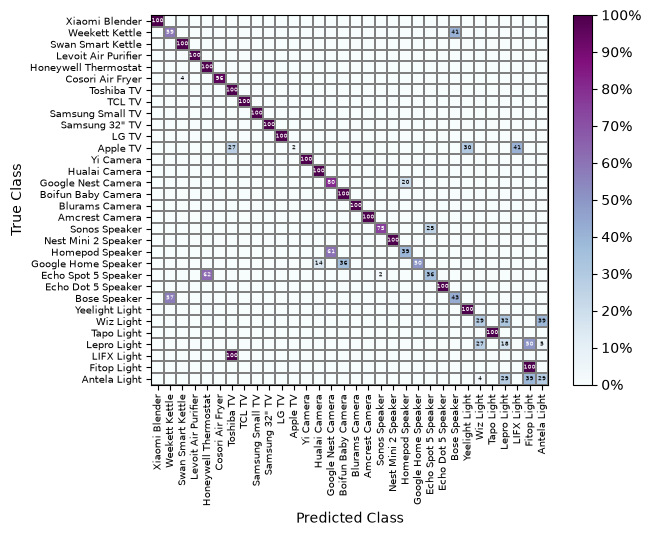

'#table(  columns: 3,  [IoT Device], [Precision], [f1 score],  [Fitop Light], [1.000], [0.691],  [Tapo Light], [1.000], [1.000],  [Yeelight Light], [1.000], [0.868],  [Echo Dot 5 Speaker], [1.000], [1.000],  [Nest Mini 2 Speaker], [1.000], [1.000],  [Amcrest Camera], [1.000], [1.000],  [Blurams Camera], [1.000], [1.000],  [Xiaomi Blender], [1.000], [1.000],  [TCL TV], [1.000], [1.000],  [Toshiba TV], [1.000], [0.612],  [Samsung 32" TV], [1.000], [1.000],  [Samsung Small TV], [1.000], [1.000],  [LG TV], [1.000], [1.000],  [Yi Camera], [1.000], [1.000],  [Hualai Camera], [1.000], [0.933],  [Boifun Baby Camera], [1.000], [0.848],  [Honeywell Thermostat], [1.000], [0.762],  [Swan Smart Kettle], [1.000], [0.982],  [Levoit Air Purifier], [1.000], [1.000],  [Cosori Air Fryer], [0.964], [0.982],  [Google Nest Camera], [0.804], [0.667],  [Sonos Speaker], [0.750], [0.848],  [Weekett Kettle], [0.589], [0.545],  [Google Home Speaker], [0.500], [0.667],  [Bose Speaker], [0.429], [0.466],  [Homepod 

,Precision,f1 score
Fitop Light,1.000,0.691
Tapo Light,1.000,1.000
Yeelight Light,1.000,0.868
Echo Dot 5 Speaker,1.000,1.000
Nest Mini 2 Speaker,1.000,1.000
Amcrest Camera,1.000,1.000
Blurams Camera,1.000,1.000
Xiaomi Blender,1.000,1.000
TCL TV,1.000,1.000
Toshiba TV,1.000,0.612


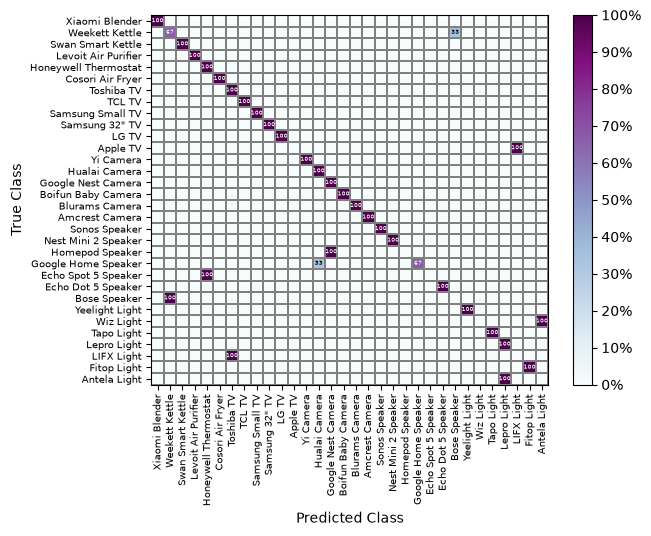

'#table(  columns: 3,  [IoT Device], [Precision], [f1 score],  [Device], [IoT Device], [IoT Device],  [Fitop Light], [1.000], [0.691],  [Tapo Light], [1.000], [1.000],  [Yeelight Light], [1.000], [0.868],  [Echo Dot 5 Speaker], [1.000], [1.000],  [Nest Mini 2 Speaker], [1.000], [1.000],  [Amcrest Camera], [1.000], [1.000],  [Blurams Camera], [1.000], [1.000],  [Xiaomi Blender], [1.000], [1.000],  [TCL TV], [1.000], [1.000],  [Toshiba TV], [1.000], [0.612],  [Samsung 32" TV], [1.000], [1.000],  [Samsung Small TV], [1.000], [1.000],  [LG TV], [1.000], [1.000],  [Yi Camera], [1.000], [1.000],  [Hualai Camera], [1.000], [0.933],  [Boifun Baby Camera], [1.000], [0.848],  [Honeywell Thermostat], [1.000], [0.762],  [Swan Smart Kettle], [1.000], [0.982],  [Levoit Air Purifier], [1.000], [1.000],  [Cosori Air Fryer], [0.964], [0.982],  [Google Nest Camera], [0.804], [0.667],  [Sonos Speaker], [0.750], [0.848],  [Weekett Kettle], [0.589], [0.545],  [Google Home Speaker], [0.500], [0.667],  [Bose

,Precision,f1 score
Device,,
Fitop Light,1.000,0.691
Tapo Light,1.000,1.000
Yeelight Light,1.000,0.868
Echo Dot 5 Speaker,1.000,1.000
Nest Mini 2 Speaker,1.000,1.000
Amcrest Camera,1.000,1.000
Blurams Camera,1.000,1.000
Xiaomi Blender,1.000,1.000
TCL TV,1.000,1.000


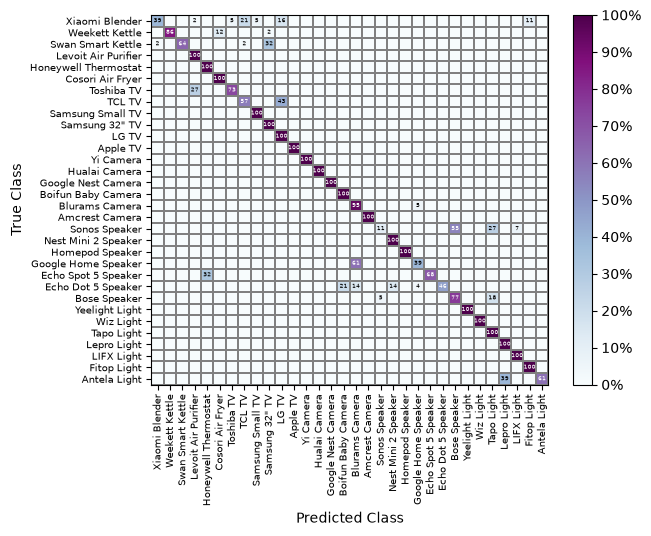

In [54]:
# | label: confusion matrix
all = Experiment(
    c,
    State.IDLE,
    Metric.MEAN,
    180,
    10,
)
graph_confusion_matrix(all)
plt.show()

typst_table(
    # pd.DataFrame.from_dict(
    #     sort_dict_by_value(all.f1_scores, reverse=True), orient="index"
    # ),
    pd.DataFrame(
        data={"Precision": all.precision, "f1 score": all.f1_scores}, index=all.devices
    ).sort_values(by=["Precision"], ascending=False),
    diag=False,
    index_title="IoT Device"
)

out = Experiment(
    c,
    State.IDLE,
    Metric.MEAN,
    600,
    60,
)
graph_confusion_matrix(out)
plt.show()

performance = pd.DataFrame(
        data={"Precision": all.precision, "f1 score": all.f1_scores}, index=all.devices
    ).sort_values(by=["Precision"], ascending=False)
performance.index.name = 'Device'
typst_table(
    # pd.DataFrame.from_dict(
    #     sort_dict_by_value(all.f1_scores, reverse=True), orient="index"
    # ),
    performance,
    diag=False,
    index_title="IoT Device"
)


# display(len([1 for score in all.f1_scores.values() if score > 0.9]))

# # include only devices from above who are not equal to 100
active = Experiment(
    c,
    State.ACTIVE,
    Metric.MEAN,
    180,
    10,
)
graph_confusion_matrix(active)

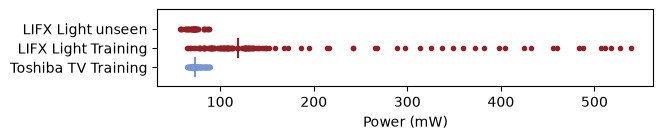

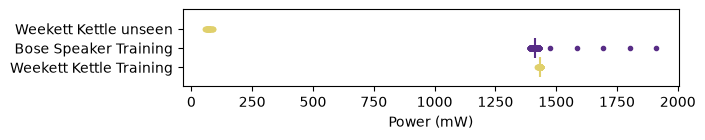

In [12]:
# | label: confused with

# for a device, see what other devices it is confused with
# [ for device, class_ in all.classes.items() if class]


# lifx = all.devices[2]


def plot_confusion(device_name):
    main_device = [device for device in all.devices if device.dir_name == device_name][
        0
    ]
    devices = list(all.classes[main_device].keys())
    if main_device not in devices:
        devices = [main_device] + devices
    indexes = [all.devices.index(device) for device in devices]
    fig, ax = plt.subplots()
    n = len(devices)

    testing = compute_profile(all, all.data[2].testing)[all.metric]
    for point in testing:
        ax.scatter(point, n, c=main_device.colour, marker=".")
    for i, (index, device) in enumerate(zip(indexes, devices)):
        data = all.data[index]
        training = compute_profile(all, data.training)[all.metric]

        # plot the training
        # TODO plot the median
        for point in training:
            ax.scatter(point, n - i - 1, c=device.colour, marker=".")
        ax.scatter(np.median(training), n - i - 1, marker="|", s=200, c=device.colour)

        # ax.scatter(point, 1, marker=".")
    ax.set_ylim((-1, n + 1))
    ax.set_yticks(
        range(n + 1),
        labels=[f"{device.name()} {"Training"}" for device in devices[::-1]]
        + [f"{main_device.name()} unseen"],
    )

    # ax.set_yticks(
    #     range(n),
    #     labels=[
    #         f"{device.name()}"
    #         for device in devices[::-1]
    #         # for type in ["unseen", "training"]
    #     ],
    # )
    ax.set_xlabel("Power (mW)")
    fig.set_figheight(n / 2)


plot_confusion("lifx")
plot_confusion("weekett")
plt.show()